# 1. Load Data

In [10]:
import pandas as pd

def load_data(data_path : str):
    df = pd.read_csv(f"{data_path}")

    return df

def save_data(df: pd.DataFrame, data_path : str):

    return df.to_csv(f"{data_path}", index = False)

credit_card_balance = load_data("D:/4. Home Credit/Dataset/CSV/credit_card_balance.csv")

In [11]:
credit_card_balance_copy = credit_card_balance.copy()

# 2. Define Customized One Hot Encoder Function

In [12]:
def OHE(df : pd.DataFrame):
    # Get categorical columns
    categorical_columns = list(df.select_dtypes(include = ['object']))

    # OHE 
    df = pd.get_dummies(df, columns = categorical_columns, dummy_na = False, drop_first = True )

    # Return df
    return df 

In [13]:
credit_card_balance_copy.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,...,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,...,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,...,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,...,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,...,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


# 3. Check Correlation and Drop High Correlation Columns

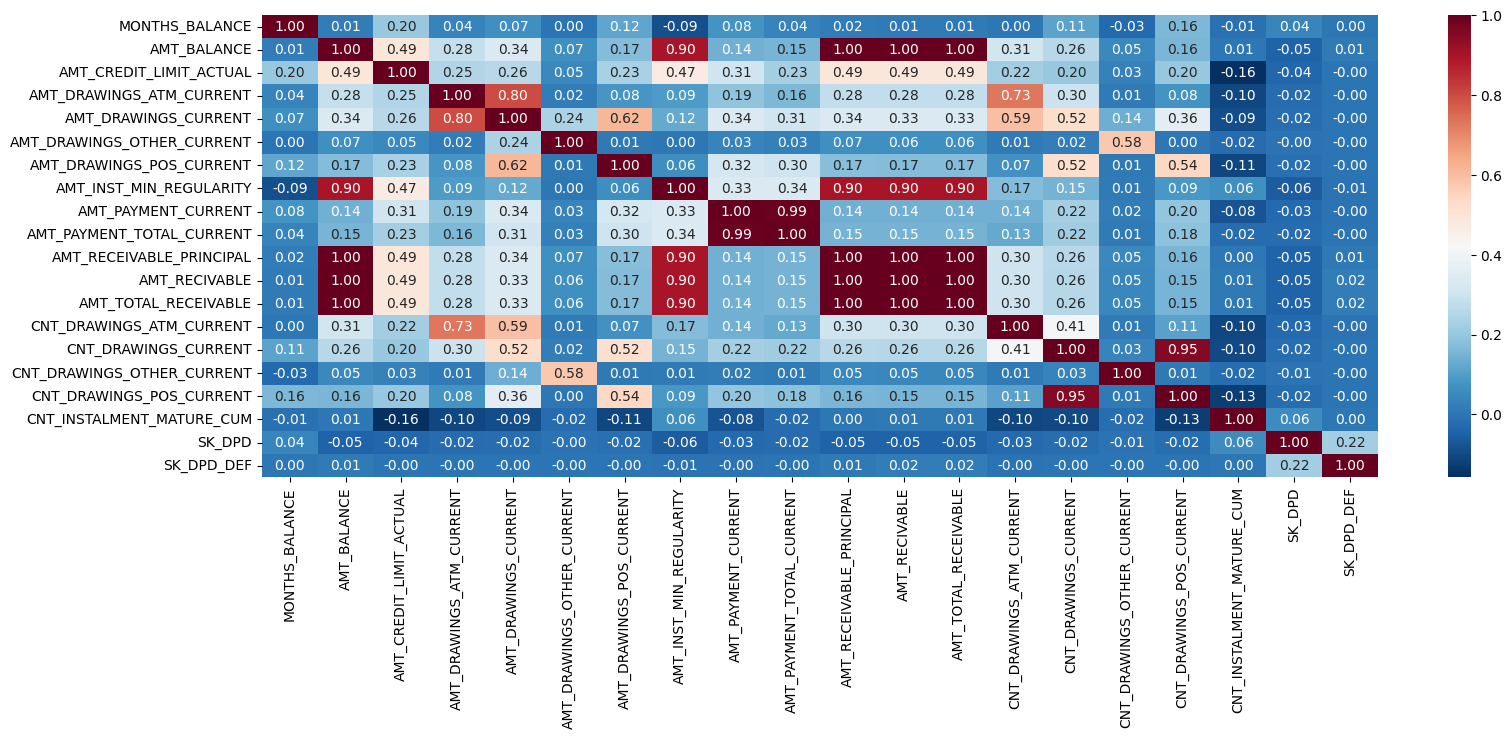

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize = (18,6))
sns.heatmap(credit_card_balance_copy.drop(columns = ['SK_ID_PREV', "SK_ID_CURR"]).corr(numeric_only = True), annot = True, fmt = '.2f', cmap = 'RdBu_r')
plt.show()

In [15]:
credit_card_balance_copy = credit_card_balance_copy.drop(columns = ['AMT_RECIVABLE'])

# 4. Data Processing

### Feature Engineering

In [16]:
# L1M, L3M, L6M
recent_features = []

for month in [1,3,6]:
    recent = credit_card_balance_copy[credit_card_balance_copy['MONTHS_BALANCE'].between(-month, 0)]
    agg = recent.groupby("SK_ID_CURR").agg(**{
        f"CREDIT_CARD_BALANCE_AMT_BALANCE_L{month}M_MEAN" : ('AMT_BALANCE','mean'),
        f"CREDIT_CARD_BALANCE_AMT_DRAWINGS_ATM_CURRENT_L{month}M_MEAN" : ('AMT_DRAWINGS_ATM_CURRENT', 'mean'),
        f"CREDIT_CARD_BALANCE_AMT_TOTAL_RECEIVABLE_L{month}M_MEAN" : ('AMT_TOTAL_RECEIVABLE', 'mean'),
        f"CREDIT_CARD_BALANCE_AMT_PAYMENT_CURRENT_L{month}M_MEAN" : ('AMT_PAYMENT_CURRENT', 'mean'),
        f"CREDIT_CARD_BALANCE_AMT_CREDIT_LIMIT_ACTUAL_L{month}M_MEAN" : ('AMT_CREDIT_LIMIT_ACTUAL', 'mean')
    })

    recent_features.append(agg)

recent_features = pd.concat(recent_features, axis = 1).reset_index()


credit_card_balance_copy['CREDIT_CARD_BALANCE_AMT_BALANCE_TO_CREDIT_LIMIT'] = credit_card_balance_copy['AMT_BALANCE'] / credit_card_balance_copy['AMT_CREDIT_LIMIT_ACTUAL']
credit_card_balance_copy['CREDIT_CARD_BALANCE_AMT_PAYMENT_TO_MIN_REGULARITY'] = credit_card_balance_copy['AMT_PAYMENT_CURRENT'] / credit_card_balance_copy['AMT_INST_MIN_REGULARITY'] 
credit_card_balance_copy['CREDIT_CARD_BALANCE_AMT_ATM_DRAWINGS_TO_TOTAL'] = credit_card_balance_copy['AMT_DRAWINGS_ATM_CURRENT'] / credit_card_balance_copy['AMT_DRAWINGS_CURRENT']
credit_card_balance_copy['CREDIT_CARD_BALANCE_DRAWINGS_TO_BALANCE'] = credit_card_balance_copy['AMT_DRAWINGS_CURRENT'] / (credit_card_balance_copy['AMT_BALANCE'].clip(lower=0) + 1)

### OHE and Aggregation To Merge Data Into Unique IDs

In [17]:
# OHE
credit_card_balance_copy = OHE(credit_card_balance_copy)

# Aggregation
credit_card_balance_numeric_aggregation = {}
credit_card_balance_OHE_aggregation = {}

# Numeric
credit_card_balance_numeric_aggregation = {
    'MONTHS_BALANCE' : ['sum','mean','min','max'],
    'AMT_BALANCE' : ['sum','mean','min','max'],
    'AMT_CREDIT_LIMIT_ACTUAL': ["sum", "mean", "max"],
    'AMT_DRAWINGS_ATM_CURRENT' : ['sum','mean','max'],
    'AMT_DRAWINGS_CURRENT' : ['sum', 'mean','max'],
    'AMT_DRAWINGS_OTHER_CURRENT' : ['sum','mean','max'],
    'AMT_DRAWINGS_POS_CURRENT' : ['sum','mean','max'],
    'AMT_INST_MIN_REGULARITY' : ['mean'],
    'AMT_PAYMENT_CURRENT' : ['sum', 'mean'],
    'AMT_PAYMENT_TOTAL_CURRENT' : ['mean'],
    'AMT_RECEIVABLE_PRINCIPAL' : ['sum', 'mean','max'],
    'AMT_TOTAL_RECEIVABLE' : ['mean'],
    'CNT_DRAWINGS_ATM_CURRENT' : ['sum','mean'],
    'CNT_DRAWINGS_CURRENT' : ['sum','mean'],
    'CNT_DRAWINGS_OTHER_CURRENT' : ['sum','mean'],
    'CNT_DRAWINGS_POS_CURRENT' : ['sum','mean'],
    'CNT_INSTALMENT_MATURE_CUM' : ['sum','mean'],
    'SK_DPD' : ['mean','max','min','sum'],
    'SK_DPD_DEF' : ['mean','max','min','sum'],
    'CREDIT_CARD_BALANCE_AMT_BALANCE_TO_CREDIT_LIMIT' : ['mean'],
    'CREDIT_CARD_BALANCE_AMT_PAYMENT_TO_MIN_REGULARITY' : ['mean'],
    'CREDIT_CARD_BALANCE_AMT_ATM_DRAWINGS_TO_TOTAL' : ['mean'],
    'CREDIT_CARD_BALANCE_DRAWINGS_TO_BALANCE' : ['mean']
}

# OHE
ohe_cols = [col for col in credit_card_balance_copy.columns if col.startswith("NAME_CONTRACT_STATUS_")]
credit_card_balance_OHE_aggregation = {col : ['mean'] for col in ohe_cols}

# Aggregation
credit_card_balance_agg = credit_card_balance_copy.groupby("SK_ID_CURR").agg({**credit_card_balance_numeric_aggregation, **credit_card_balance_OHE_aggregation})
credit_card_balance_agg.columns = [f"CREDIT_CARD_{col}_{status}".upper() for col, status in credit_card_balance_agg.columns]
credit_card_balance_agg = credit_card_balance_agg.reset_index()
credit_card_balance_agg = credit_card_balance_agg.merge(recent_features, on = 'SK_ID_CURR', how = 'left')
credit_card_balance_agg.head()

C:\Users\Admin\AppData\Local\Temp\ipykernel_4112\2489354095.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = list(df.select_dtypes(include = ['object']))


,SK_ID_CURR,CREDIT_CARD_MONTHS_BALANCE_SUM,CREDIT_CARD_MONTHS_BALANCE_MEAN,CREDIT_CARD_MONTHS_BALANCE_MIN,CREDIT_CARD_MONTHS_BALANCE_MAX,CREDIT_CARD_AMT_BALANCE_SUM,CREDIT_CARD_AMT_BALANCE_MEAN,CREDIT_CARD_AMT_BALANCE_MIN,CREDIT_CARD_AMT_BALANCE_MAX,CREDIT_CARD_AMT_CREDIT_LIMIT_ACTUAL_SUM,...,CREDIT_CARD_BALANCE_AMT_BALANCE_L3M_MEAN,CREDIT_CARD_BALANCE_AMT_DRAWINGS_ATM_CURRENT_L3M_MEAN,CREDIT_CARD_BALANCE_AMT_TOTAL_RECEIVABLE_L3M_MEAN,CREDIT_CARD_BALANCE_AMT_PAYMENT_CURRENT_L3M_MEAN,CREDIT_CARD_BALANCE_AMT_CREDIT_LIMIT_ACTUAL_L3M_MEAN,CREDIT_CARD_BALANCE_AMT_BALANCE_L6M_MEAN,CREDIT_CARD_BALANCE_AMT_DRAWINGS_ATM_CURRENT_L6M_MEAN,CREDIT_CARD_BALANCE_AMT_TOTAL_RECEIVABLE_L6M_MEAN,CREDIT_CARD_BALANCE_AMT_PAYMENT_CURRENT_L6M_MEAN,CREDIT_CARD_BALANCE_AMT_CREDIT_LIMIT_ACTUAL_L6M_MEAN
0,100006,-21,-3.5,-6,-1,0.000,0.000000,0.0,0.00,1620000,...,0.0,NaN,0.0,NaN,270000.0,0.0,NaN,0.0,NaN,270000.0
1,100011,-2849,-38.5,-75,-2,4031676.225,54482.111149,0.0,189000.00,12150000,...,0.0,0.0,0.0,563.355,90000.0,0.0,0.0,0.0,563.355,90000.0
2,100013,-4656,-48.5,-96,-1,1743352.245,18159.919219,0.0,161420.22,12645000,...,0.0,0.0,0.0,274.320,45000.0,0.0,0.0,0.0,274.320,45000.0
3,100021,-170,-10.0,-18,-2,0.000,0.000000,0.0,0.00,11475000,...,0.0,NaN,0.0,NaN,675000.0,0.0,NaN,0.0,NaN,675000.0
4,100023,-60,-7.5,-11,-4,0.000,0.000000,0.0,0.00,1080000,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,225000.0


# 5. Save Data

In [18]:
save_data(credit_card_balance_agg, "D:/4. Home Credit/Dataset/CSV/card_balanced_agg_final.csv")